# Comparação de detectores de objeto (box-only) — Side-Scan Sonar (MILCO/NOMBO)

**Objetivo deste notebook:** treinar e comparar **4 arquiteturas de detecção de objeto**
no dataset *Side-scan sonar imaging for Mine detection* (Santos et al., 2024 — Figshare/Kaggle),
focando **apenas na localização do objeto (bounding box)**, sem classificar MILCO vs NOMBO.
Por isso, todas as anotações são remapeadas para **uma única classe `object`**. A classificação
(MILCO/NOMBO) já é feita por você em uma etapa posterior, fora deste notebook.

Modelos comparados:

1. **Modelo A** — YOLO (anchor-free) com cabeça extra P2 para objetos pequenos.
2. **Modelo B** — o mesmo backbone + módulo de atenção (CBAM) / SPD-Conv, focado em alvos pequenos.
3. **Modelo C** — Cascade R-CNN (duas etapas, refinamento de box em múltiplos estágios) via MMDetection,
   com um **fallback** em Faster R-CNN (torchvision) caso o MMDetection não instale no seu ambiente.
4. **Modelo D** — RT-DETR (detector baseado em transformer, sem anchors/NMS).

> ⚠️ **Antes de rodar:** ajuste os caminhos em `CONFIG` na célula 2, e confirme o formato real dos
> arquivos `.txt` de anotação (célula 4) — o dataset original documenta bounding boxes, mas você
> deve verificar se estão em `xmin ymin xmax ymax` (pixels) ou já normalizados. Abra 2-3 `.txt`
> manualmente e ajuste a função `parse_annotation()` se necessário.

> Este notebook constrói o pipeline completo (dados → treino → avaliação unificada), mas **não foi
> executado aqui** — não há GPU/dataset neste ambiente. Rode em Colab, Kaggle ou sua máquina com GPU.


## 1. Instalação de dependências

In [1]:
# Núcleo: YOLO (Modelos A, B, D) + utilitários de avaliação
# !pip install -q -U ultralytics pycocotools opencv-python-headless matplotlib pandas seaborn tqdm

# # MMDetection (Modelo C — Cascade R-CNN). Pode falhar dependendo da versão de torch/CUDA
# # instalada; se falhar, use o fallback em torchvision (Faster R-CNN) fornecido na Seção 7.
# !pip install -q -U mmengine
# !pip install -q -U "mmcv>=2.0.0" -f https://download.openmmlab.com/mmcv/dist/cu121/torch2.1/index.html || pip install -q mmcv
# !pip install -q -U mmdet

# Fallback (Modelo C alternativo) — já vem com torchvision, normalmente presente
import torchvision
print("torchvision:", torchvision.__version__)


torchvision: 0.29.0+cu126


## 2. Configuração geral

In [2]:
import os, json, glob, random, shutil
from pathlib import Path
import numpy as np
import pandas as pd

CONFIG = {
    # Pasta com os dados originais já descompactados: subpastas por ano ou tudo junto,
    # contendo pares "XXXX_YYYY.jpg" + "XXXX_YYYY.txt"
    "RAW_DATA_DIR": "../raw_data",

    # Pasta de trabalho onde tudo será gerado (datasets convertidos, pesos, resultados)
    "WORK_DIR": "./work",

    # Proporções do split (mantém proporção por ano, ver Seção 3)
    "SPLIT": {"train": 0.70, "val": 0.15, "test": 0.15},

    "SEED": 42,
    "IMG_SIZE": 640,
    "EPOCHS": 200,         # com pesos pre-treinados + patience, converge sem gastar tudo
    "PATIENCE": 50,        # para o treino sozinho se nao melhorar por N epocas seguidas
    "BATCH": 16,
    "DEVICE": 0,            # 0 = primeira GPU; "cpu" se não houver GPU
}

random.seed(CONFIG["SEED"])
np.random.seed(CONFIG["SEED"])

WORK = Path(CONFIG["WORK_DIR"])
WORK.mkdir(parents=True, exist_ok=True)
print("Config OK. Diretorio de trabalho:", WORK.resolve())


Config OK. Diretorio de trabalho: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work


## 3. Preparação dos dados

Passos:
1. Ler cada par imagem/anotação.
2. **Remapear toda anotação para a classe única `0 = object`** (ignorando MILCO/NOMBO neste momento).
3. Dividir em train/val/test.
4. Gerar dataset no formato YOLO (`images/`, `labels/`) + `data.yaml`.
5. Gerar também um `instances_test.json` no formato **COCO**, usado depois para avaliar
   os 4 modelos com a mesma métrica (`pycocotools`), independente do framework de cada um.


In [3]:
def parse_annotation(txt_path, img_w, img_h, box_format="center"):
    """
    Le o .txt de anotacao original do dataset e devolve uma lista de boxes
    no formato [xmin, ymin, xmax, ymax] em pixels.

    IMPORTANTE (corrigido): segundo a documentacao oficial do dataset
    (Santos et al., 2024, Data in Brief - doi.org/10.1016/j.dib.2024.110132),
    as coordenadas no .txt sao "classe x y w h", JA normalizadas (0-1) como
    percentual da imagem. NAO sao xmin/ymin/xmax/ymax em pixels.

    Falta apenas confirmar se (x, y) e o CENTRO da caixa (padrao YOLO) ou o
    CANTO SUPERIOR-ESQUERDO. Rode a celula de diagnostico visual logo abaixo
    ANTES de continuar - ela desenha as duas interpretacoes sobre uma imagem
    real para voce escolher visualmente. Depois, ajuste box_format aqui:
    "center" (x,y = centro, o mais provavel/compativel com YOLO) ou "corner"
    (x,y = canto superior-esquerdo).
    """
    boxes = []
    if not os.path.exists(txt_path):
        return boxes
    with open(txt_path, "r") as f:
        for line in f.read().strip().splitlines():
            if not line.strip():
                continue
            parts = line.strip().split()
            # parts[0] = classe original (0=MILCO, 1=NOMBO) -> ignorada, remapeada para "object"
            x, y, w, h = map(float, parts[1:5])  # ja normalizados (0-1)

            if box_format == "center":
                xc, yc, bw, bh = x, y, w, h
            elif box_format == "corner":
                bw, bh = w, h
                xc, yc = x + w / 2, y + h / 2
            else:
                raise ValueError("box_format deve ser 'center' ou 'corner'")

            xmin = (xc - bw / 2) * img_w
            xmax = (xc + bw / 2) * img_w
            ymin = (yc - bh / 2) * img_h
            ymax = (yc + bh / 2) * img_h
            boxes.append([xmin, ymin, xmax, ymax])
    return boxes


In [4]:
from PIL import Image

def list_pairs(raw_dir):
    """Encontra todos os pares (imagem, anotacao) recursivamente em raw_dir."""
    imgs = sorted(glob.glob(os.path.join(raw_dir, "**", "*.jpg"), recursive=True))
    pairs = []
    for img_path in imgs:
        txt_path = os.path.splitext(img_path)[0] + ".txt"
        pairs.append((img_path, txt_path))
    print(f"Encontrados {len(pairs)} pares imagem/anotacao em {raw_dir}")
    return pairs

pairs = list_pairs(CONFIG["RAW_DATA_DIR"])
assert len(pairs) > 0, "Nenhum par imagem/anotacao encontrado - confira RAW_DATA_DIR."


Encontrados 1170 pares imagem/anotacao em ../raw_data


### 3.1 Diagnóstico visual — confirme a convenção da caixa ANTES de converter tudo

Esta célula pega 4 imagens aleatórias do seu dataset e desenha a caixa nas duas
interpretações possíveis lado a lado: **"center"** (x,y = centro, padrão YOLO) em
verde e **"corner"** (x,y = canto superior-esquerdo) em vermelho. Olhe qual das
duas realmente contorna o objeto (MILCO/NOMBO) na imagem — é bem visível a
diferença quando está errado (a caixa fica deslocada ou fora do objeto).

Depois de identificar a correta, ajuste `box_format="center"` (ou `"corner"`) na
chamada de `parse_annotation()` dentro de `build_yolo_dataset()` (célula seguinte)
e em `yolo_split_to_coco()`, se aplicável.

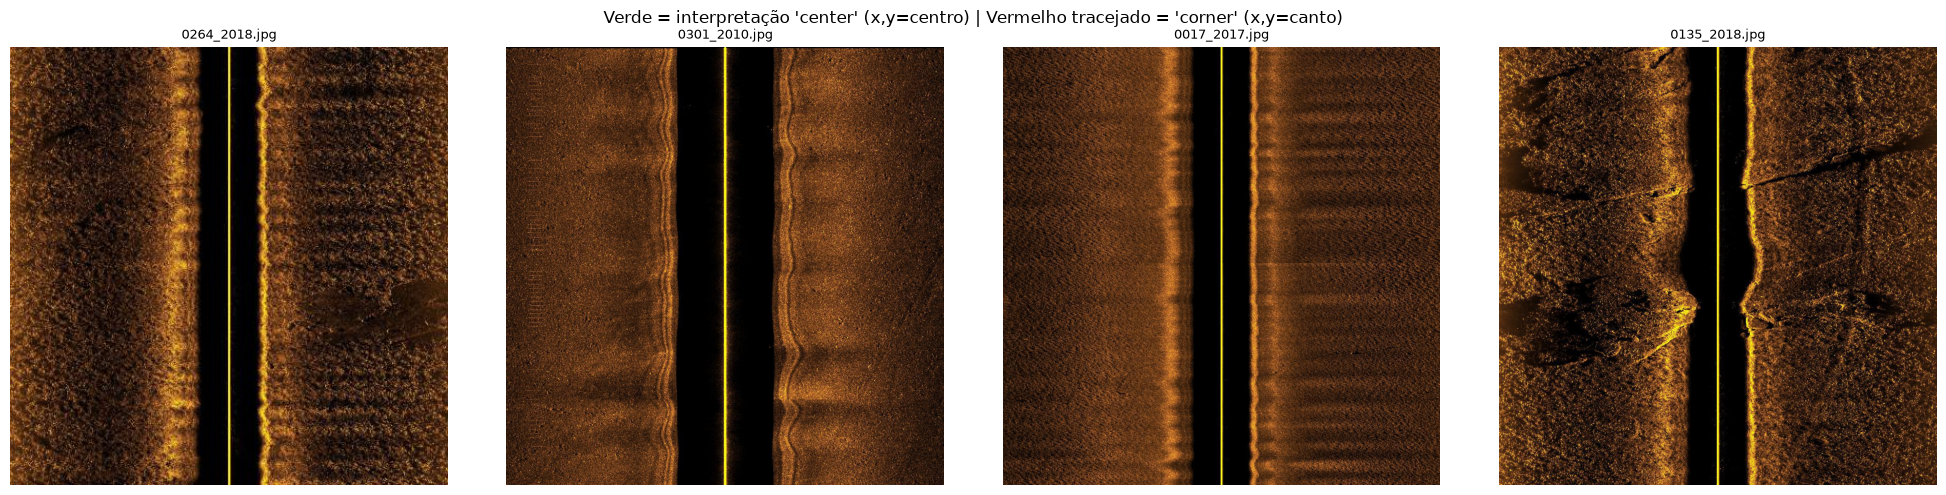

Qual contorna melhor o objeto nas 4 imagens? Use esse box_format nas células seguintes.


In [5]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import random as _random

sample_pairs = _random.Random(0).sample(pairs, min(4, len(pairs)))

fig, axes = plt.subplots(1, len(sample_pairs), figsize=(5 * len(sample_pairs), 5))
if len(sample_pairs) == 1:
    axes = [axes]

for ax, (img_path, txt_path) in zip(axes, sample_pairs):
    img = Image.open(img_path)
    w, h = img.size
    ax.imshow(img, cmap="gray")
    ax.set_title(Path(img_path).name, fontsize=9)

    boxes_center = parse_annotation(txt_path, w, h, box_format="center")
    boxes_corner = parse_annotation(txt_path, w, h, box_format="corner")

    for (xmin, ymin, xmax, ymax) in boxes_center:
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                  linewidth=2, edgecolor="lime", facecolor="none", label="center")
        ax.add_patch(rect)
    for (xmin, ymin, xmax, ymax) in boxes_corner:
        rect = patches.Rectangle((xmin, ymin), xmax - xmin, ymax - ymin,
                                  linewidth=2, edgecolor="red", facecolor="none",
                                  linestyle="--", label="corner")
        ax.add_patch(rect)
    ax.axis("off")

fig.suptitle("Verde = interpretação 'center' (x,y=centro) | Vermelho tracejado = 'corner' (x,y=canto)")
plt.tight_layout()
plt.show()

print("Qual contorna melhor o objeto nas 4 imagens? Use esse box_format nas células seguintes.")


In [6]:
def stratify_split(pairs, split_ratios, seed=42):
    """Split simples aleatorio (troque por estratificado por ano se preferir)."""
    rnd = random.Random(seed)
    shuffled = pairs[:]
    rnd.shuffle(shuffled)
    n = len(shuffled)
    n_train = int(n * split_ratios["train"])
    n_val = int(n * split_ratios["val"])
    train = shuffled[:n_train]
    val = shuffled[n_train:n_train + n_val]
    test = shuffled[n_train + n_val:]
    return {"train": train, "val": val, "test": test}

splits = stratify_split(pairs, CONFIG["SPLIT"], CONFIG["SEED"])
for k, v in splits.items():
    print(k, len(v))


train 819
val 175
test 176


In [7]:
def build_yolo_dataset(splits, work_dir):
    """Cria estrutura images/labels (train/val/test) com classe unica 'object'."""
    yolo_dir = Path(work_dir) / "yolo_dataset"
    for split_name, items in splits.items():
        img_out = yolo_dir / "images" / split_name
        lbl_out = yolo_dir / "labels" / split_name
        img_out.mkdir(parents=True, exist_ok=True)
        lbl_out.mkdir(parents=True, exist_ok=True)
        for img_path, txt_path in items:
            img = Image.open(img_path)
            w, h = img.size
            boxes = parse_annotation(txt_path, w, h, box_format="center")  # ajuste conforme diagnostico acima

            stem = Path(img_path).stem
            shutil.copy(img_path, img_out / f"{stem}.jpg")

            lines = []
            for (xmin, ymin, xmax, ymax) in boxes:
                xc = ((xmin + xmax) / 2) / w
                yc = ((ymin + ymax) / 2) / h
                bw = (xmax - xmin) / w
                bh = (ymax - ymin) / h
                lines.append(f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}")
            with open(lbl_out / f"{stem}.txt", "w") as f:
                f.write("\n".join(lines))
    return yolo_dir

yolo_dir = build_yolo_dataset(splits, CONFIG["WORK_DIR"])
print("Dataset YOLO criado em:", yolo_dir.resolve())


Dataset YOLO criado em: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset


In [8]:
data_yaml_path = yolo_dir / "data.yaml"
data_yaml_content = f"""path: {yolo_dir.resolve()}
train: images/train
val: images/val
test: images/test
names:
  0: object
"""
data_yaml_path.write_text(data_yaml_content)
print(data_yaml_content)


path: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: object



### 3.2 Correção crítica — IDs de imagem consistentes entre GT e predições

A Ultralytics salva `predictions.json` usando o **nome do arquivo (stem)** como
`image_id` (ex.: `"0099_2015"`), não um índice sequencial. Se o nosso
`coco_test_gt.json` usar IDs diferentes (1, 2, 3...), o `pycocotools` não
consegue casar as predições com o ground truth e a avaliação falha
(`Results do not correspond to current coco set`). A função abaixo replica
exatamente a lógica da Ultralytics para que os IDs sempre batam, não importa
qual dos 4 modelos gerou as predições.

In [9]:
def coco_image_id(file_stem):
    """Replica exatamente a logica da Ultralytics (pred_to_json) para gerar
    o 'image_id' usado no predictions.json: int(stem) se for puramente
    numerico, senao a string do stem. Usar a MESMA funcao aqui para o
    ground-truth COCO garante que os ids batam com as predicoes de
    qualquer um dos 4 modelos na avaliacao unificada (Secao 9)."""
    return int(file_stem) if file_stem.isnumeric() else file_stem


In [10]:
def yolo_split_to_coco(yolo_dir, split_name, out_json):
    """Converte um split YOLO (classe unica) para anotacao COCO (ground truth),
    usada depois para avaliar todos os modelos com pycocotools."""
    img_dir = Path(yolo_dir) / "images" / split_name
    lbl_dir = Path(yolo_dir) / "labels" / split_name

    images, annotations = [], []
    ann_id = 1
    categories = [{"id": 1, "name": "object"}]

    for img_path in sorted(img_dir.glob("*.jpg")):
        img_id = coco_image_id(img_path.stem)
        img = Image.open(img_path)
        w, h = img.size
        images.append({
            "id": img_id, "file_name": img_path.name, "width": w, "height": h
        })
        lbl_path = lbl_dir / (img_path.stem + ".txt")
        if lbl_path.exists():
            for line in lbl_path.read_text().strip().splitlines():
                if not line.strip():
                    continue
                _, xc, yc, bw, bh = map(float, line.split())
                xc, yc, bw, bh = xc * w, yc * h, bw * w, bh * h
                xmin, ymin = xc - bw / 2, yc - bh / 2
                annotations.append({
                    "id": ann_id, "image_id": img_id, "category_id": 1,
                    "bbox": [xmin, ymin, bw, bh],
                    "area": bw * bh, "iscrowd": 0
                })
                ann_id += 1

    coco = {"images": images, "annotations": annotations, "categories": categories}
    Path(out_json).write_text(json.dumps(coco))
    print(f"COCO gt salvo em {out_json} | imgs={len(images)} anns={len(annotations)}")
    return out_json

coco_test_gt = yolo_split_to_coco(yolo_dir, "test", WORK / "coco_test_gt.json")


COCO gt salvo em work\coco_test_gt.json | imgs=176 anns=109


## 4. Utilitário de avaliação unificado (COCOeval)

Todos os 4 modelos terão suas predições no split de teste exportadas para o **mesmo formato
COCO de detecção** (lista de `{image_id, category_id, bbox, score}`), permitindo comparar
mAP@50, mAP@50-95 e AR (average recall) na mesma métrica, independente do framework usado
para treinar cada um.


In [11]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

def evaluate_coco(gt_json_path, pred_json_path, model_name):
    coco_gt = COCO(str(gt_json_path))
    coco_dt = coco_gt.loadRes(str(pred_json_path))
    ev = COCOeval(coco_gt, coco_dt, iouType="bbox")
    ev.evaluate()
    ev.accumulate()
    print(f"\n===== {model_name} =====")
    ev.summarize()
    stats = ev.stats  # ordem padrao do COCOeval
    return {
        "model": model_name,
        "mAP_50_95": stats[0],
        "mAP_50": stats[1],
        "mAP_75": stats[2],
        "mAP_small": stats[3],
        "AR_100": stats[8],
        "AR_small": stats[9],
    }

results_summary = []  # cada modelo vai adicionar seu dict aqui na Secao 9


## 5. Modelo A — YOLO (anchor-free) com cabeça extra P2

Adiciona uma cabeça de detecção extra em resolução mais fina (stride 4, camada **P2**),
além das P3/P4/P5 padrão do YOLOv8/v11 — é o que mais ajuda quando o problema é
**objeto pequeno sendo perdido** (baixo recall) no sonar. A Ultralytics já disponibiliza a
variante `*-p2.yaml`; se sua versão instalada não tiver esse arquivo, baixe o `.yaml`
correspondente do repositório oficial da Ultralytics (`ultralytics/cfg/models/v8/yolov8-p2.yaml`).


In [12]:
from ultralytics import YOLO

MODEL_A_NAME = "modelA_yolo_p2"

# Se 'yolov8n-p2.yaml' nao existir na sua instalacao, baixe o .yaml oficial do
# repositorio Ultralytics (models/v8/yolov8-p2.yaml) e aponte o caminho local aqui.
model_a = YOLO("yolov8n-p2.yaml")
model_a.load("yolov8n.pt")  # transfere pesos compativeis (acelera MUITO a convergencia)

model_a.train(
    data=str(data_yaml_path),
    epochs=CONFIG["EPOCHS"],
    imgsz=CONFIG["IMG_SIZE"],
    batch=CONFIG["BATCH"],
    device=CONFIG["DEVICE"],
    single_cls=True,          # box-only: ignora multiclasse, foca em localizar objeto
    mosaic=0.0,                # desliga mosaic - tende a prejudicar objetos ja pequenos em sonar
    patience=CONFIG["PATIENCE"],
    project=str(WORK / "runs"),
    name=MODEL_A_NAME,
    seed=CONFIG["SEED"],
)


Transferred 219/437 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.165 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=work\yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, ma

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, method='weighted_average', num_output_channels=3), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))
WARNING val: Slow image access detected (ping: 0.10.0 ms, read: 25.024.3 MB/s, size: 146.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\val... 175 images, 134 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 175/175 862.2it/s 0.2s0.0s
val: New cache created: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\val.cache
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: AdamW(lr=0.002, momentum=0.9) with parameter groups 70 weight(decay=0.0), 79 weight(decay=0.0005), 78 bias(decay=0.0)
Pl

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001AEC947F2D0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

In [13]:
# Avaliacao no split de teste, exportando predicoes em formato COCO (save_json=True)
metrics_a = model_a.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=CONFIG["IMG_SIZE"],
    device=CONFIG["DEVICE"],
    save_json=True,
    project=str(WORK / "runs"),
    name=MODEL_A_NAME + "_val",
)

# Ultralytics salva as predicoes em <save_dir>/predictions.json
pred_a_path = Path(metrics_a.save_dir) / "predictions.json"
print("Predicoes Modelo A em:", pred_a_path)


Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
YOLOv8n-p2 summary (fused): 90 layers, 2,921,172 parameters, 0 gradients, 12.2 GFLOPs
WARNING val: Slow image access detected (ping: 2.23.9 ms, read: 21.822.7 MB/s, size: 152.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\test... 176 images, 130 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176 189.9it/s 0.9s.2s
val: New cache created: D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.0s/it 21.6s0.2s
                   all        176        109      0.831       0.63      0.706      0.355
Speed: 2.7ms preprocess, 7.7ms inference, 0.0ms loss, 0.9ms postprocess per image
Saving D

In [14]:
results_summary.append(evaluate_coco(coco_test_gt, pred_a_path, "A - YOLO+P2"))


loading annotations into memory...
Done (t=0.04s)
creating index...
index created!
Loading and preparing results...
DONE (t=0.02s)
creating index...
index created!
Running per image evaluation...
Evaluate annotation type *bbox*
DONE (t=0.07s).
Accumulating evaluation results...
DONE (t=0.01s).

===== A - YOLO+P2 =====
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=   all | maxDets=100 ] = 0.356
 Average Precision  (AP) @[ IoU=0.50      | area=   all | maxDets=100 ] = 0.704
 Average Precision  (AP) @[ IoU=0.75      | area=   all | maxDets=100 ] = 0.330
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= small | maxDets=100 ] = 0.342
 Average Precision  (AP) @[ IoU=0.50:0.95 | area=medium | maxDets=100 ] = 0.405
 Average Precision  (AP) @[ IoU=0.50:0.95 | area= large | maxDets=100 ] = 0.000
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets=  1 ] = 0.205
 Average Recall     (AR) @[ IoU=0.50:0.95 | area=   all | maxDets= 10 ] = 0.476
 Average Recall     (AR) @[ IoU=0.50:0.9

## 6. Modelo B — mesmo backbone + atenção (CBAM) para alvos pequenos

Insere blocos **CBAM** (Convolutional Block Attention Module) no neck, próximos às camadas
de resolução mais fina, para reforçar features relevantes de objetos pequenos em fundo ruidoso
(reverberação do sonar). Se sua versão da Ultralytics já suportar `CBAM` nativamente no parser
de `.yaml` (>= 8.1), basta referenciá-lo na arquitetura; caso contrário, registre o módulo
manualmente como mostrado abaixo.


In [15]:
import torch
import torch.nn as nn

class CBAM(nn.Module):
    """CBAM com inicializacao 'lazy': descobre o numero real de canais no
    primeiro forward, em vez de depender do valor (nao escalado) vindo do .yaml.
    Isso evita o erro de mismatch de canais causado pelo width_multiple da escala
    (ex.: 'n' = 0.25x) nao ser aplicado a modulos customizados."""
    def __init__(self, c1=None, reduction=16, kernel_size=7):
        super().__init__()
        self.reduction = reduction
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.conv_spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid_channel = nn.Sigmoid()
        self.sigmoid_spatial = nn.Sigmoid()
        self._fc = None  # construido dinamicamente no primeiro forward

    def _build_fc(self, c, device, dtype):
        hidden = max(c // self.reduction, 1)
        self._fc = nn.Sequential(
            nn.Conv2d(c, hidden, 1, bias=False), nn.ReLU(inplace=True),
            nn.Conv2d(hidden, c, 1, bias=False)
        ).to(device=device, dtype=dtype)
        self.add_module("fc", self._fc)  # registra como submodulo p/ aparecer em .parameters()

    def forward(self, x):
        if self._fc is None:
            self._build_fc(x.shape[1], x.device, x.dtype)
        ca = self.sigmoid_channel(self._fc(self.avg_pool(x)) + self._fc(self.max_pool(x)))
        x = x * ca
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        sa = self.sigmoid_spatial(self.conv_spatial(torch.cat([avg_out, max_out], dim=1)))
        return x * sa

# Registra o modulo no parser de arquiteturas da Ultralytics para poder usa-lo em .yaml
import ultralytics.nn.modules as um
import ultralytics.nn.tasks as ut
um.CBAM = CBAM
ut.CBAM = CBAM
print("CBAM registrado no parser da Ultralytics.")


CBAM registrado no parser da Ultralytics.


In [16]:
# Arquitetura Modelo B: parte do yolov8n-p2.yaml e insere CBAM apos os blocos do neck
# que alimentam as cabecas de deteccao (P2/P3/P4). Ajuste os indices de camada (`from`)
# conforme a numeracao exibida por `model_a.model` (Modelo A) se seu yaml-base for diferente.

yaml_b = WORK / "yolov8n_p2_cbam.yaml"
yaml_b_content = """
# Baseado em yolov8n-p2.yaml + CBAM antes de cada cabeca de deteccao
nc: 1
scales:
  n: [0.33, 0.25, 1024]
backbone:
  - [-1, 1, Conv, [64, 3, 2]]
  - [-1, 1, Conv, [128, 3, 2]]
  - [-1, 3, C2f, [128, True]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [-1, 6, C2f, [256, True]]
  - [-1, 1, Conv, [512, 3, 2]]
  - [-1, 6, C2f, [512, True]]
  - [-1, 1, Conv, [1024, 3, 2]]
  - [-1, 3, C2f, [1024, True]]
  - [-1, 1, SPPF, [1024, 5]]
head:
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 6], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 4], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]
  - [-1, 1, nn.Upsample, [None, 2, "nearest"]]
  - [[-1, 2], 1, Concat, [1]]
  - [-1, 3, C2f, [128]]
  - [-1, 1, CBAM, [128]]
  - [-1, 1, Conv, [256, 3, 2]]
  - [[-1, 15], 1, Concat, [1]]
  - [-1, 3, C2f, [256]]
  - [-1, 1, CBAM, [256]]
  - [-1, 1, Conv, [512, 3, 2]]
  - [[-1, 12], 1, Concat, [1]]
  - [-1, 3, C2f, [512]]
  - [-1, 1, CBAM, [512]]
  - [-1, 1, Conv, [1024, 3, 2]]
  - [[-1, 9], 1, Concat, [1]]
  - [-1, 3, C2f, [1024]]
  - [[19, 22, 25, 28], 1, Detect, [nc]]
"""
yaml_b.write_text(yaml_b_content)
print("Arquitetura do Modelo B salva em:", yaml_b)
print("Confira os indices 'from' (ex.: [-1, 6], [19, 22, 25, 28]) contra a topologia real")
print("exibida por model_a.model antes de treinar - arquiteturas .yaml sao sensiveis a isso.")


Arquitetura do Modelo B salva em: work\yolov8n_p2_cbam.yaml
Confira os indices 'from' (ex.: [-1, 6], [19, 22, 25, 28]) contra a topologia real
exibida por model_a.model antes de treinar - arquiteturas .yaml sao sensiveis a isso.


In [17]:
MODEL_B_NAME = "modelB_yolo_p2_cbam"
model_b = YOLO(str(yaml_b))
model_b.load("yolov8n.pt")  # transfere as camadas compativeis do backbone/neck padrao

model_b.train(
    data=str(data_yaml_path),
    epochs=CONFIG["EPOCHS"],
    imgsz=CONFIG["IMG_SIZE"],
    batch=CONFIG["BATCH"],
    device=CONFIG["DEVICE"],
    single_cls=True,
    mosaic=0.0,
    patience=CONFIG["PATIENCE"],
    project=str(WORK / "runs"),
    name=MODEL_B_NAME,
    seed=CONFIG["SEED"],
)


Transferred 214/452 items from pretrained weights
New https://pypi.org/project/ultralytics/8.4.165 available  Update with 'pip install -U ultralytics'
Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=work\yolo_dataset\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, ma

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\autograd\graph.py:1072: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      1/200      3.43G      4.506      34.33      3.944          3        640: 100% ━━━━━━━━━━━━ 52/52 1.4it/s 36.9s0.3ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.1s/it 18.4s0.4s5
                   all        175         75          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      2/200      3.97G      3.638      10.73      4.099          9        640: 0% ──────────── 0/52  0.2s

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\autograd\graph.py:1072: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


      2/200      3.97G      3.428      23.24      3.127          0        640: 100% ━━━━━━━━━━━━ 52/52 4.1it/s 12.6s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 3.9it/s 1.5s0.3s
                   all        175         75          0          0          0          0

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      3/200      3.97G      3.178      12.97      3.101          4        640: 0% ──────────── 0/52  0.2s

...

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\autograd\graph.py:1072: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


    199/200      3.97G      1.374     0.9355      1.379          3        640: 100% ━━━━━━━━━━━━ 52/52 4.1it/s 12.8s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 4.5it/s 1.3s0.3s
                   all        175         75        0.8      0.587      0.671      0.343

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
    200/200      3.97G      1.738      1.479       1.39         13        640: 0% ──────────── 0/52  0.3s

C:\Users\Usuário\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\torch\autograd\graph.py:1072: UserWarning: adaptive_max_pool2d_backward_cuda does not have a deterministic implementation, but you set 'torch.use_deterministic_algorithms(True, warn_only=True)'. You can file an issue at https://github.com/pytorch/pytorch/issues to help us prioritize adding deterministic support for this operation. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\Context.cpp:190.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


    200/200      3.97G      1.333     0.9315      1.308          0        640: 100% ━━━━━━━━━━━━ 52/52 4.1it/s 12.7s0.5s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 4.4it/s 1.4s0.3s
                   all        175         75      0.841      0.563      0.667      0.344

200 epochs completed in 0.834 hours.
Optimizer stripped from D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelB_yolo_p2_cbam\weights\last.pt, 7.0MB
Optimizer stripped from D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelB_yolo_p2_cbam\weights\best.pt, 7.0MB

Validating D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelB_yolo_p2_cbam\weights\best.pt...
Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
YOLOv8n_p2_cbam summary (fused): 114 layers, 3,271,514 parameters, 0 gradients, 13.0 GFLOPs
                 Class     Images  Instances      Box(P   

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x000001AF364CC5D0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.0480

In [ ]:
metrics_b = model_b.val(
    data=str(data_yaml_path),
    split="test",
    imgsz=CONFIG["IMG_SIZE"],
    device=CONFIG["DEVICE"],
    save_json=True,
    project=str(WORK / "runs"),
    name=MODEL_B_NAME + "_val",
)
pred_b_path = Path(metrics_b.save_dir) / "predictions.json"
results_summary.append(evaluate_coco(coco_test_gt, pred_b_path, "B - YOLO+P2+CBAM"))


Ultralytics 8.4.163  Python-3.11.9 torch-2.14.0+cu126 CUDA:0 (NVIDIA GeForce RTX 3050, 8192MiB)
YOLOv8n_p2_cbam summary (fused): 114 layers, 3,271,514 parameters, 0 gradients, 13.0 GFLOPs
WARNING val: Slow image access detected (ping: 0.40.2 ms, read: 8.212.2 MB/s, size: 99.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\work\yolo_dataset\labels\test.cache... 176 images, 130 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 176/176  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 11/11 2.0s/it 22.5s0.2s
                   all        176        109      0.763      0.633      0.672      0.325
Speed: 3.3ms preprocess, 8.0ms inference, 0.0ms loss, 0.9ms postprocess per image
Saving D:\testte\SEPARACAO_MODELS\TESTE_BOX_YOLO\runs\detect\work\runs\modelB_yolo_p2_cbam_val\predictions.json.

: 

## 9. Comparação unificada

In [ ]:
df_results = pd.DataFrame(results_summary)
df_results = df_results.set_index("model")
df_results.style.format("{:.3f}").background_gradient(cmap="Greens", axis=0)


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

df_results[["mAP_50", "mAP_50_95"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("mAP por modelo")
axes[0].set_ylabel("mAP")
axes[0].tick_params(axis="x", rotation=20)

df_results[["AR_100", "AR_small"]].plot(kind="bar", ax=axes[1], color=["#4c72b0", "#dd8452"])
axes[1].set_title("Average Recall por modelo")
axes[1].set_ylabel("AR")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(WORK / "comparacao_modelos.png", dpi=150)
plt.show()


## 10. Conclusões

Preencha após rodar os experimentos:

- **Qual modelo teve maior `mAP_50_95`?** (indica qualidade geral de localização, incluindo IoU alto)
- **Qual teve maior `AR_small`?** (indica quem melhor recupera os objetos pequenos — geralmente
  o ponto mais crítico em sonar)
- **Algum modelo tem muito mais falsos positivos que os outros?** (compare precisão nos
  `ev.stats` completos, não só o resumo — rode `evaluate_coco` com `iouThrs` customizado se quiser
  inspecionar limiares específicos)
- **Custo computacional/tempo de treino valeu o ganho de mAP?** (relevante se a etapa de detecção
  também precisar rodar embarcada no AUV depois)

Com o modelo de detecção escolhido aqui, a próxima etapa é plugar sua etapa de classificação
já validada (recorte da box → classificador MILCO/NOMBO).
